In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import stats
# import scipy.stats

url = "https://raw.githubusercontent.com/nkmwicz/data-for-students/refs/heads/main/soccer-players.csv"
# https://raw.githubusercontent.com/nkmwicz/data-for-students/
# refs/heads/main/soccer-players.csv

df = pd.read_csv(url)
df.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,right,184.0,NaN,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,left,190.0,NaN,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,NaN,NaN,NaN,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,NaN,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus Football Club,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,right,194.0,NaN,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,FC Bayern München,100000.0,3000000.0


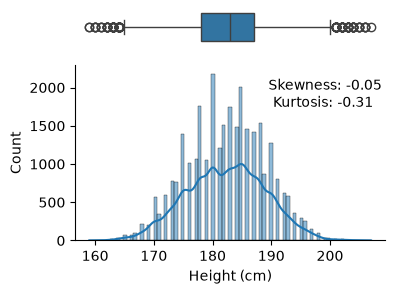

In [21]:
fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=[1,5], figsize=(4,3))

# Rid ourselves of mistakes
df = df.loc[df['height_in_cm']>140]

skewness = stats.skew(df['height_in_cm'], nan_policy="omit")
kurt = stats.kurtosis(df['height_in_cm'], nan_policy="omit")

txt = f"""Skewness: {skewness:.2f}
Kurtosis: {kurt:.2f} 
"""

plt.figtext(x=0.75, y=0.5, s=txt, transform=fig.transFigure, ha="center")
box = sns.boxplot(data=df, x="height_in_cm", ax=ax1)
hist = sns.histplot(data=df, x="height_in_cm", ax=ax2, kde=True)
ax1.spines.clear()
ax1.set(xticks=[], xlabel="", yticks=[])
ax2.spines[["right", "top"]].set_visible(False)
ax2.set(xlabel="Height (cm)")

plt.show()

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 30055 entries, 0 to 32400
Data columns (total 23 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   player_id                             30055 non-null  int64  
 1   first_name                            28024 non-null  str    
 2   last_name                             30055 non-null  str    
 3   name                                  30055 non-null  str    
 4   last_season                           30055 non-null  int64  
 5   current_club_id                       30055 non-null  int64  
 6   player_code                           30055 non-null  str    
 7   country_of_birth                      28161 non-null  str    
 8   city_of_birth                         28489 non-null  str    
 9   country_of_citizenship                29707 non-null  str    
 10  date_of_birth                         30019 non-null  str    
 11  sub_position                   

In [23]:
df.describe()

,player_id,last_season,current_club_id,height_in_cm,market_value_in_eur,highest_market_value_in_eur
count,3.005500e+04,30055.000000,30055.000000,30055.000000,2.914400e+04,2.914400e+04
mean,3.260050e+05,2019.352554,4952.292431,182.313026,1.696020e+06,3.847007e+06
std,2.665954e+05,3.964365,11889.432752,6.709060,6.537328e+06,9.890951e+06
min,1.000000e+01,2012.000000,3.000000,159.000000,1.000000e+04,1.000000e+04
25%,9.944650e+04,2016.000000,405.000000,178.000000,1.000000e+05,3.000000e+05
50%,2.649660e+05,2020.000000,1082.000000,183.000000,2.500000e+05,8.000000e+05
75%,4.883295e+05,2023.000000,3205.000000,187.000000,7.000000e+05,3.000000e+06
max,1.306851e+06,2024.000000,110302.000000,207.000000,2.000000e+08,2.000000e+08


In [ ]:
from numpy import nan

def evaluate_df(df):

    rows = []
    columns = [
        "column_name", 
        "is_numeric", 
        "mean", 
        "median", 
        "min", 
        "max", 
        "Q25", 
        "Q75", 
        "std", 
        "num_null", 
        "num_unique", 
        "uniques<5"]

    for col in df.columns:
        col_name = col 
        is_numeric = pd.api.types.is_numeric_dtype(df[col])
        mean= nan 
        median= nan 
        minimum= nan 
        maximum= nan 
        q25= nan 
        q75= nan 
        std= nan 
        num_null= df[col].isna().sum()
        num_unique= nan 
        uniques5= nan

        if is_numeric:
            mean= df[col].mean()
            median= df[col].median()
            minimum= df[col].min()
            maximum= df[col].max()
            q25= df[col].quantile(0.25)
            q75= df[col].quantile(0.75)
            std= df[col].std()
        else:
            num_unique= df[col].nunique() 
            uniques5= df[col].unique() if num_unique <= 5 else nan

        row = [
            col_name,
            is_numeric,
            mean,
            median,
            minimum,
            maximum,
            q25,
            q75,
            std,
            num_null,
            num_unique,
            uniques5,
        ]
        rows.append(row)

    eval_df = pd.DataFrame(data=rows, columns=columns)

    return eval_df.sort_values(by="is_numeric")


,column_name,is_numeric,mean,median,min,max,Q25,Q75,std,num_null,num_unique,uniques<5
11,sub_position,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107,13.0,NaN
17,image_url,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,25452.0,NaN
13,foot,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1221,3.0,"[right, left, both, nan]"
12,position,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,5.0,"[Attack, Goalkeeper, Midfield, Defender, Missing]"
18,url,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,30055.0,NaN
10,date_of_birth,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36,9007.0,NaN
9,country_of_citizenship,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,348,183.0,NaN
15,contract_expiration_date,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10916,108.0,NaN
8,city_of_birth,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1566,8352.0,NaN
6,player_code,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,29368.0,NaN
